# Module 05 Practice Lab 02: Creating Dashboards (Australia Wildfire)

CISC7204 Assignment 02 | mc635497 DUAN QINGRU



In [ ]:
import pandas as pd
import dash
from dash import html, dcc
from dash.dependencies import Input, Output, State
import plotly.graph_objects as go
import plotly.express as px
from dash import no_update
import datetime as dt

# Create app
app = dash.Dash(__name__)

# Clear the layout and do not display exception till callback gets executed
app.config.suppress_callback_exceptions = True

# Read the wildfire data into pandas dataframe
df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Historical_Wildfires.csv')

# Extract year and month from the date column
df['Month'] = pd.to_datetime(df['Date']).dt.month_name()  # used for the names of the months
df['Year'] = pd.to_datetime(df['Date']).dt.year

# Layout Section of Dash

# Task 2.1 Add the Title to the Dashboard
app.layout = html.Div(children=[html.H1('Australia Wildfire Dashboard',
                                        style={'textAlign': 'center', 'color': '#503D36',
                                               'font-size': 26}),
# TASK 2.2: Add the radio items and a dropdown right below the first inner division
     # outer division starts
     html.Div([
                   # First inner divsion for adding dropdown helper text for Selected Drive wheels
                    html.Div([
                            html.H2('Select Region:', style={'margin-right': '2em'}),

                    # Radio items to select the region
                    dcc.RadioItems([{"label":"New South Wales","value": "NSW"},
                                    {"label":"Northern Territory","value": "NT"},
                                    {"label":"Queensland","value": "QL"},
                                    {"label":"South Australia","value": "SA"},
                                    {"label":"Tasmania","value": "TA"},
                                    {"label":"Victoria","value": "VI"},
                                    {"label":"Western Australia","value": "WA"}], "NSW", id='region', inline=True)]),
                    # Dropdown to select year
                    html.Div([
                            html.H2('Select Year:', style={'margin-right': '2em'}),
                        dcc.Dropdown(df.Year.unique(), value=2005, id='year')
                        # notice the use of unique() from pandas to fetch the values of year from the dataframe for dropdown
                    ]),
# TASK 2.3: Add two empty divisions for output inside the next inner division.
         # Second Inner division for adding 2 inner divisions for 2 output graphs
                    html.Div([

                        html.Div([ ], id='plot1'),
                        html.Div([ ], id='plot2')
                    ], style={'display': 'flex'}),

    ])
    # outer division ends

])
# layout ends

# TASK 2.4: Add the Ouput and input components inside the app.callback decorator.
# Place to add @app.callback Decorator
@app.callback([Output(component_id='plot1', component_property='children'),
               Output(component_id='plot2', component_property='children')],
              [Input(component_id='region', component_property='value'),
               Input(component_id='year', component_property='value')])
# TASK 2.5: Add the callback function.
# Place to define the callback function.
def reg_year_display(input_region, input_year):

    # data
    region_data = df[df['Region'] == input_region]
    y_r_data = region_data[region_data['Year'] == input_year]
    # Plot one - Monthly Average Estimated Fire Area
    est_data = y_r_data.groupby('Month')['Estimated_fire_area'].mean().reset_index()
    fig1 = px.pie(est_data, values='Estimated_fire_area', names='Month',
                  title="{} : Monthly Average Estimated Fire Area in year {}".format(input_region, input_year))
    # Plot two - Monthly Average Count of Pixels for Presumed Vegetation Fires
    veg_data = y_r_data.groupby('Month')['Count'].mean().reset_index()
    fig2 = px.bar(veg_data, x='Month', y='Count',
                  title='{} : Average Count of Pixels for Presumed Vegetation Fires in year {}'.format(input_region, input_year))
    return [dcc.Graph(figure=fig1),
            dcc.Graph(figure=fig2)]

# 在 PyCharm/终端中运行: python Dash_wildfire.py  （app.run() 已在 notebook 中注释）


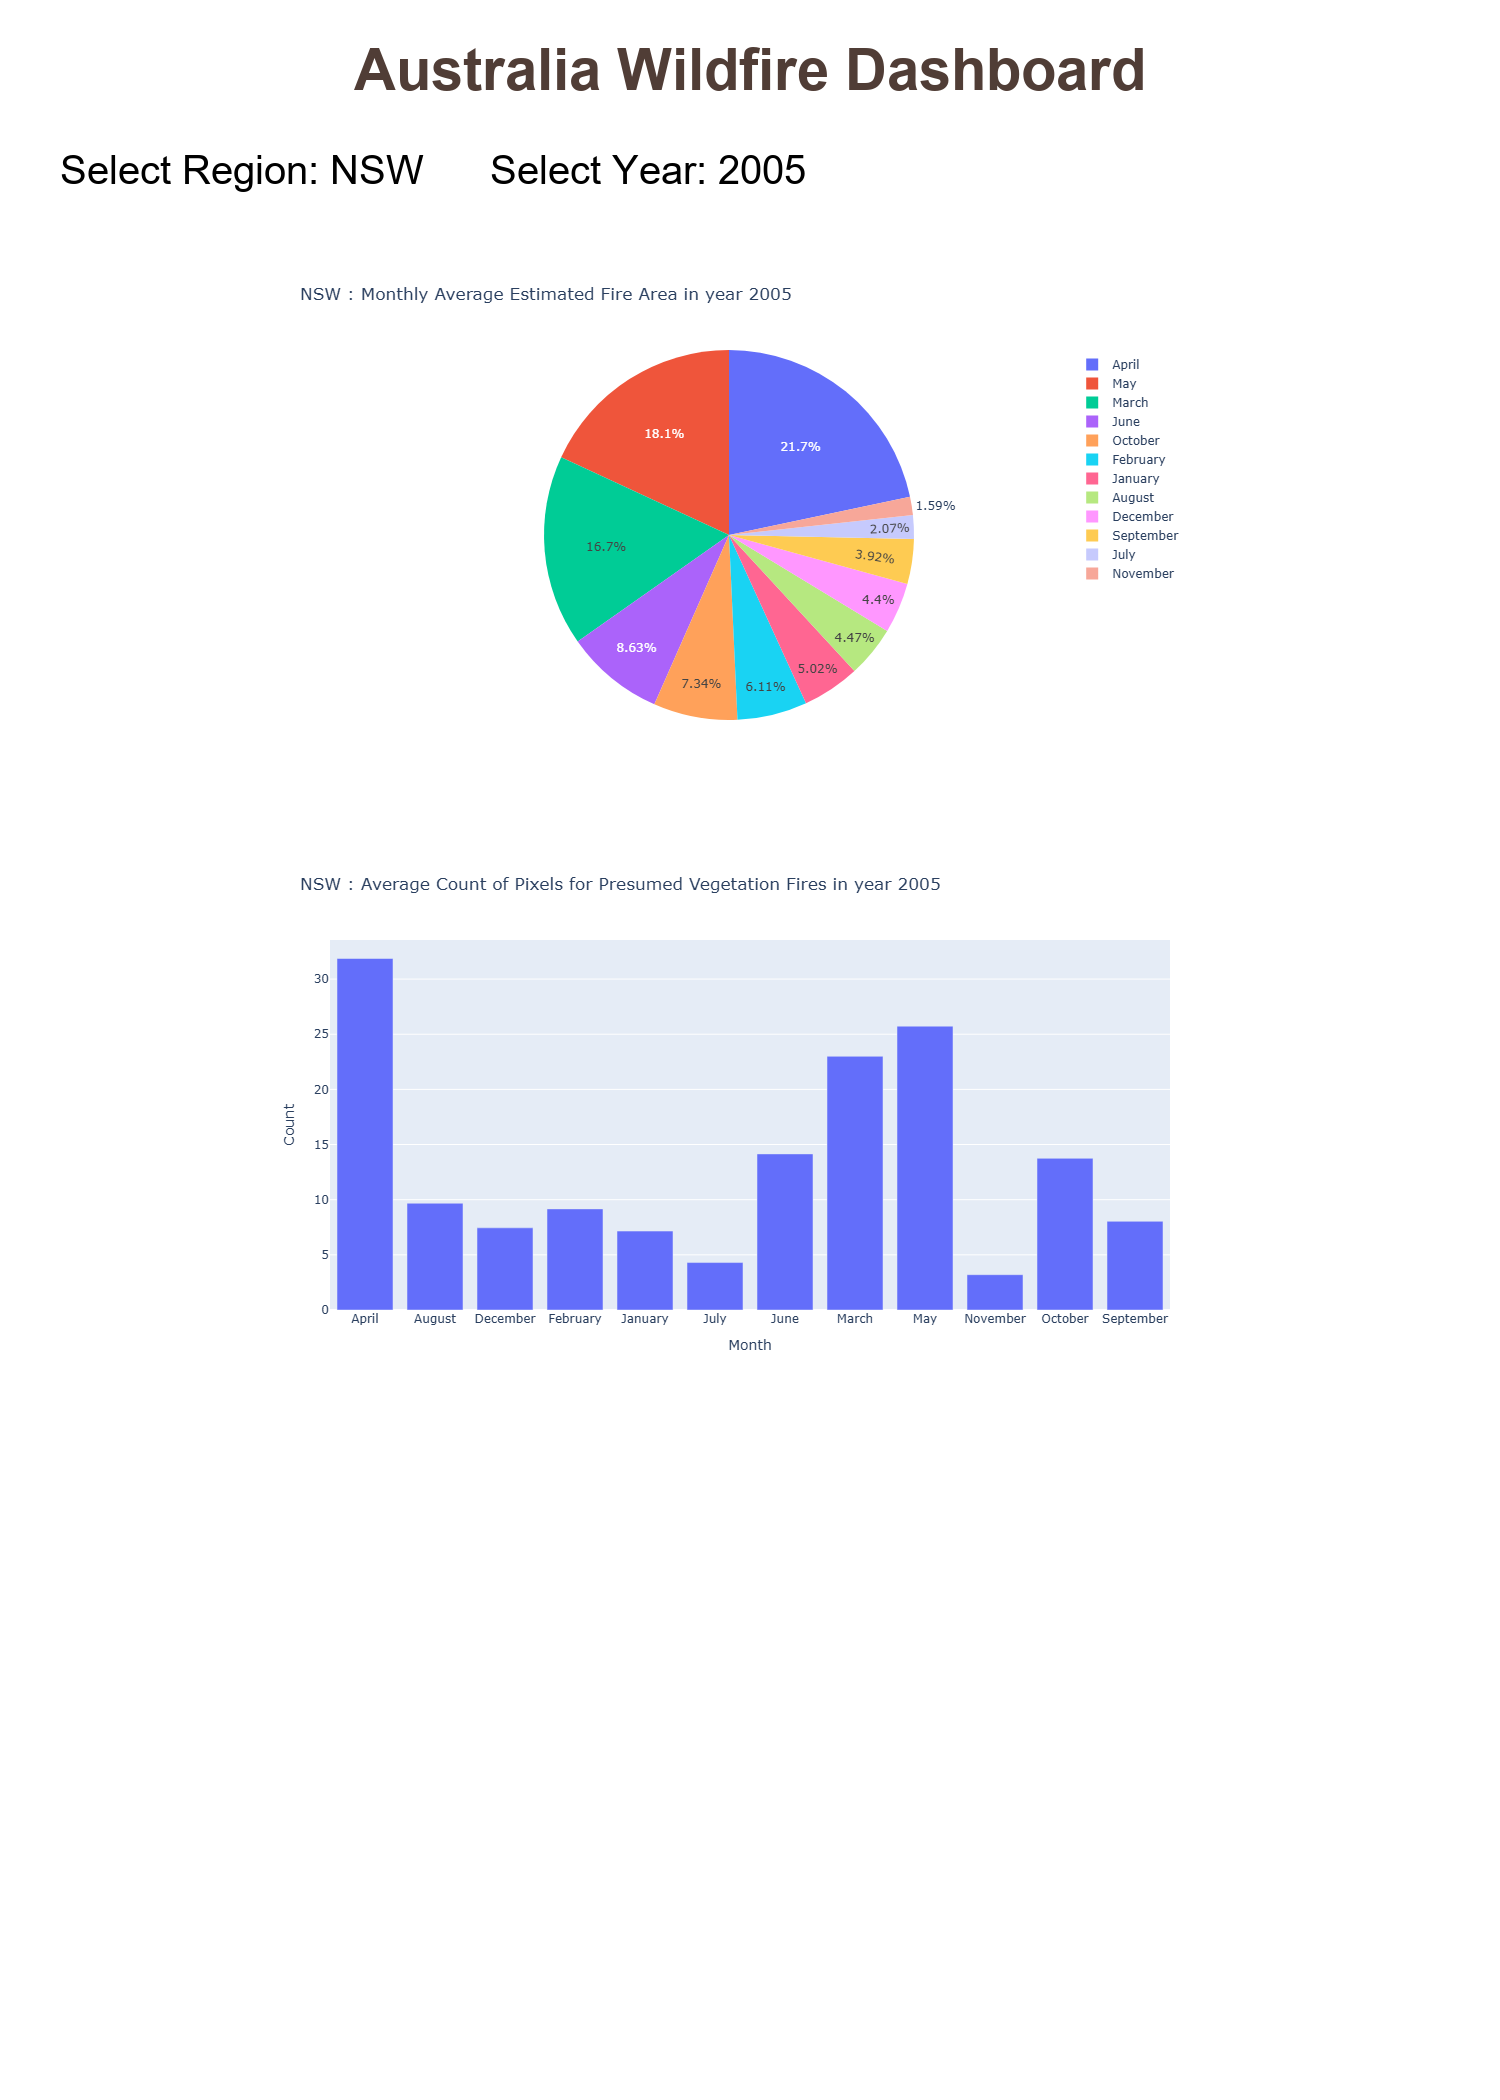

In [ ]:
from IPython.display import Image
Image(filename='practice_p2_dashboard_NSW_2005.png')  # 运行截图：NSW + 2005 饼图与柱状图